<img src="http://imgur.com/1ZcRyrc.png" style="float: left; margin: 20px; height: 55px">

# Neural Networks with Keras

---

_Created by: Husain Amer_, 
_Updated by: Mohamad Hindi_


## Load Dataset

In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data Visualization
import seaborn as sns
import matplotlib.pyplot as plt

%matplotlib inline

In [2]:
# Load data
df = pd.read_csv('data/housing.csv')
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


## Basic EDA

In [3]:
# Get a general glimpse of your data.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [4]:
df.isnull().mean().sort_values(ascending=False)*100

total_bedrooms        1.002907
longitude             0.000000
latitude              0.000000
housing_median_age    0.000000
total_rooms           0.000000
population            0.000000
households            0.000000
median_income         0.000000
median_house_value    0.000000
ocean_proximity       0.000000
dtype: float64

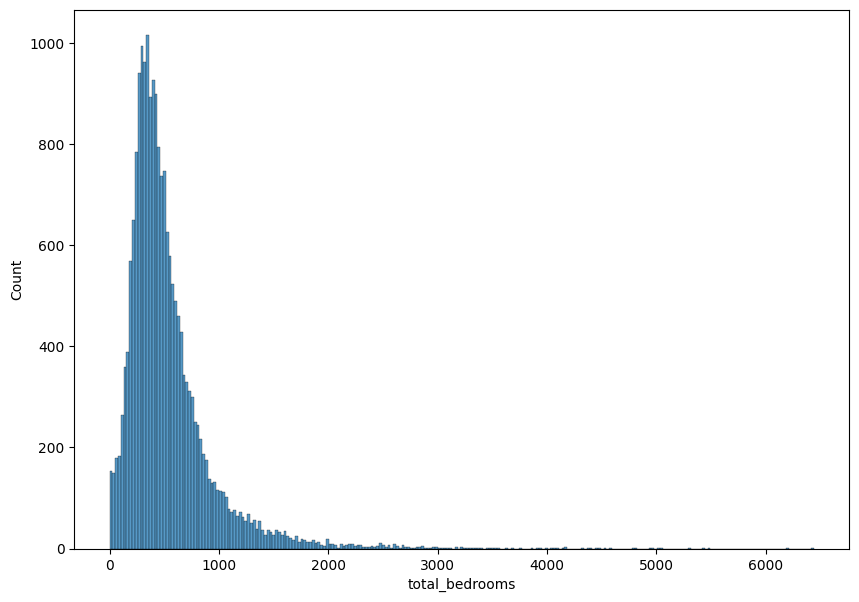

In [5]:
plt.figure(figsize=(10, 7))

sns.histplot(data=df, x="total_bedrooms");

In [6]:
# Drop missing values

df = df.dropna()

In [7]:
df.shape

(20433, 10)

## Understanding Data Splitting For Neural Networks

When training a neural network, you must split your dataset into three distinct subsets: **Train**, **Validation**, and **Test**. 

`Keras does not support stratification natively within model.fit()`. 
For classification, this will cause a problem. 

**Best Practice for Neural Network** Split your data before modeling into three part:

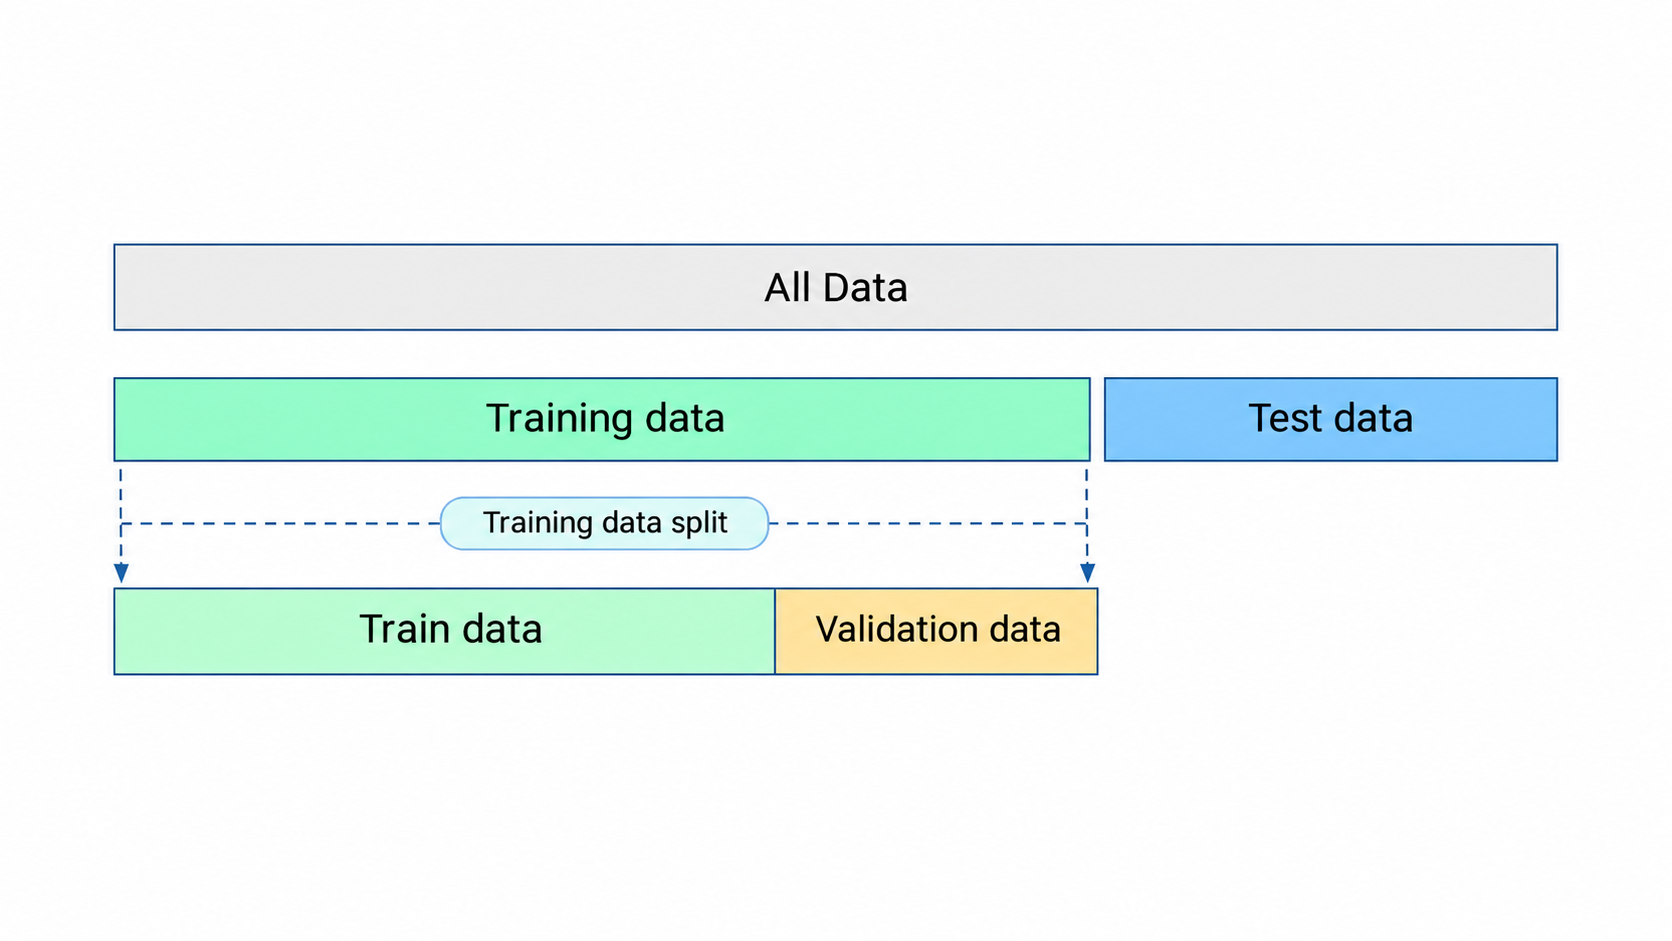

#### 1. The Training Set (The Textbook)
* **Purpose:** This is the data the neural network actually looks at to learn.
* **How it works:** During the training loop, the network uses this data to adjust its **weights** and **biases** via backpropagation.

#### 2. The Validation Set (The Practice Quiz)
* **Purpose:** This data evaluates the model *during* training to fine-tune settings.
* **How it works:** The model does not learn its weights from this data. Instead, the it uses the validation score to choose **hyperparameters** (like learning rate, number of layers, or node count) and to decide when to stop training (**early stopping**).


#### 3. The Test Set (The Final Exam)
* **Purpose:** This data provides an unbiased, final evaluation of the model's real-world performance.
* **How it works:** This dataset is locked away until training is completely finished. It is only used *once* at the very end to see how well the network performs on truly unseen data.
---

#### 📊 Typical Split Ratios

Depending on the size of your total dataset, data scientists generally use these proportions:

| Dataset Size | Train | Validation | Test |
| :--- | :--- | :--- | :--- |
| **Traditional (Small/Medium Data)** | 60% | 20% | 20% |
| **Modern Deep Learning (Millions of Rows)** | 98% | 1% | 1% |

*Note: In modern deep learning, a 1% split can still mean tens of thousands of samples, which is more than enough to validate and test a model accurately.*


In [8]:
# Import libraries
from sklearn.model_selection import train_test_split


# Select features and target
X = df.drop(columns = ["median_house_value", "ocean_proximity"])
y = df['median_house_value']

# Split data into train, val and test sets
X_train_all,X_test, y_train_all, y_test=train_test_split(X,y,test_size=.20,
                                                         random_state=42)

X_train, X_val, y_train,y_val = train_test_split(X_train_all,y_train_all,
                                                 test_size=.20,random_state=42)

## Your First Neural Network model

### The Three Basic Layers
A neural network is organized into three main parts:
* **Input Layer:** This is where the computer takes in raw information. For example, it might look at the pixels of a photo of a cat.
* **Hidden Layers:** These are the middle layers that do the math. They guess patterns, like looking for pointy ears or whiskers.
* **Output Layer:** This layer gives the final answer. It tells you, "Yes, this is a cat!"
---


### Create your network topology
We'll create a simple network with:
- an input layer
    - Always specify the number of features here
- one hidden layer with 3 neurons. 
    - As a general rule, you should use `relu` as your activation function for all hidden layers.
- an output layer. 
    - For *all* regression problems, your output layer will be 1 neuron with `linear` as activation function.
---

### The full model
Creating a model in `keras` entails a few steps:
1. Create your network topology
2. Compile your model
3. Fit your model

We'll cover each step in the cells below.

---


In [9]:
# %pip install keras
# %pip install tensorflow

In [10]:
# How can I dynamically retrieve the number of features?

X.shape[1]

8

In [11]:
#Step0: Import
from keras.models import Sequential
from keras.layers import Dense, Input

# Step 1: Architecture
model = Sequential()

# Input layer
model.add( Input( shape = (X.shape[1],) ) ) # shape is number of features passed

# Hidden layer
model.add( Dense(3) ) 

# Output layer
model.add( Dense(1)) 

# Note:default activation for the output layer is linear

# Step 2: Compilation
# Regression loss function to use Mean Square Error (MSE) 
# or Mean Absolute Error (MAE)
model.compile(loss='mse') 

#S Step 3: Fitting 
model.fit(X_train,
          y_train)


  1/409 [..............................] - ETA: 1:08 - loss: 61009092608.0000

2026-11-10 15:59:58.412199: W tensorflow/core/platform/profile_utils/cpu_utils.cc:128] Failed to get CPU frequency: 0 Hz


409/409 [==============================] - 0s 353us/step - loss: 54993190912.0000


### How It Learns
Neural networks do not just follow strict rules. They learn by making mistakes and fixing them. 

1. **The Guess:** The network looks at a picture and makes a guess.
2. **The Check:** A **loss function** calculates how wrong the guess was. 
3. **The Fix:** The network uses **backpropagation**. This fancy word just means it goes backward to adjust its internal settings, called **weights**.
4. **Repeat:** It does this thousands of times until it stops making mistakes.

_🔗 Resources:_
- [Backpropagation Simulation](https://lnkd.in/p/d3N5qtSS)
- [Backpropagation, intuitively | Deep Learning Chapter 3](https://www.youtube.com/watch?v=Ilg3gGewQ5U)


### Weights (a, b)

In [12]:
model.weights

[<tf.Variable 'dense/kernel:0' shape=(8, 3) dtype=float32, numpy=
 array([[ 0.44795215,  0.81203455,  0.28912622],
        [-1.1495835 , -1.1339893 ,  0.55038   ],
        [ 0.27632576, -0.56547725,  0.408865  ],
        [-0.55071014, -0.16385031,  0.15819046],
        [-0.68190145, -0.0802487 ,  0.03575568],
        [-0.7515959 ,  0.27562886,  0.80031717],
        [-0.63875556, -1.0529158 ,  0.3946977 ],
        [-1.0368825 , -0.661471  ,  0.639843  ]], dtype=float32)>,
 <tf.Variable 'dense/bias:0' shape=(3,) dtype=float32, numpy=array([-0.41875246, -0.41465408,  0.42029262], dtype=float32)>,
 <tf.Variable 'dense_1/kernel:0' shape=(3, 1) dtype=float32, numpy=
 array([[-1.3707337 ],
        [-0.7231483 ],
        [ 0.66012233]], dtype=float32)>,
 <tf.Variable 'dense_1/bias:0' shape=(1,) dtype=float32, numpy=array([0.41560736], dtype=float32)>]

### Model Summary

In [13]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 3)                 27        
                                                                 
 dense_1 (Dense)             (None, 1)                 4         
                                                                 
Total params: 31
Trainable params: 31
Non-trainable params: 0
_________________________________________________________________


#### Deep Network

In [14]:
# use multiple hidden layers with different neurons

# Step 1:
model=Sequential()

model.add(Input(shape=(X.shape[1],)))  #input layer with 1 feature
model.add(Dense(30))  # hidden layer with 30 neurons (nodes)
model.add(Dense(20))  # hidden layer with 20 neurons
model.add(Dense(15))  # hidden layer with 15 neurons
model.add(Dense(1))  # output layer

#Step 2:
# loss function to use Mean Square Error (MSE) or Mean Absolute Error (MAE)
model.compile(loss='mse') 


#Step 3:
model.fit(X_train,
          y_train)


409/409 [==============================] - 0s 369us/step - loss: 30720460800.0000


In [15]:
# model summary
model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_2 (Dense)             (None, 30)                270       
                                                                 
 dense_3 (Dense)             (None, 20)                620       
                                                                 
 dense_4 (Dense)             (None, 15)                315       
                                                                 
 dense_5 (Dense)             (None, 1)                 16        
                                                                 
Total params: 1,221
Trainable params: 1,221
Non-trainable params: 0
_________________________________________________________________


# Activation Functions

An **activation function** is a mathematical formula placed at the end of each neuron in a neural network. Its main job is to determine whether a neuron should "fire" (turn on) or stay silent based on the incoming information.

Without activation functions, a neural network is just a giant linear regression model, completely unable to learn complex patterns.

---

### 🧠 The Core Purpose: Adding Non-Linearity

Real-world data is complex and rarely follows a straight line. 
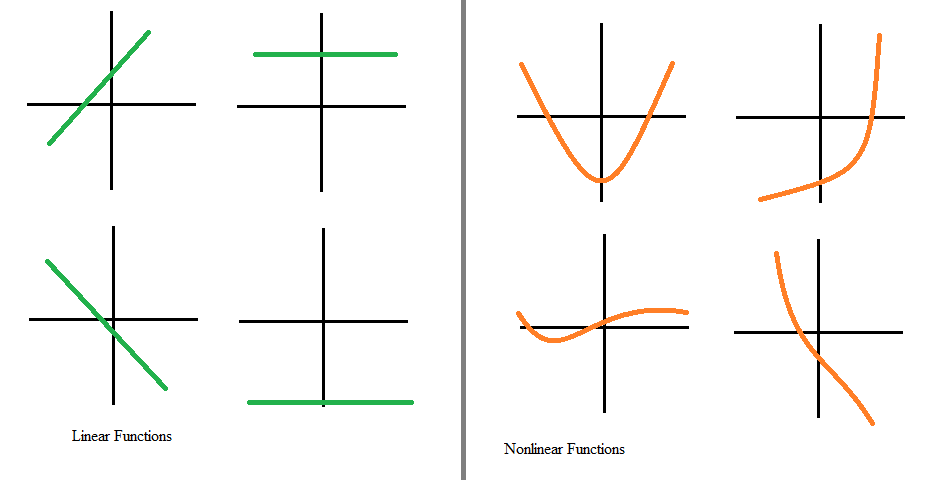

* **Linear vs. Non-Linear:** If you don't use an activation function, multiplying inputs by weights over and over only creates a straight line (\(y = mx + b\)). No matter how many thousands of hidden layers you add, the model remains a simple linear calculator.
* **The Magic Ingredient:** Activation functions introduce **non-linearity** (bends, curves, and thresholds). This allows the network to learn complex boundaries, like recognizing shapes in images, predicting stock trends, or understanding human speech.

---

### 🧱 The Most Common Activation Functions


#### 1. ReLU (Rectified Linear Unit)
* **The Formula:** $\text{ReLU}(x) = \max(0, x)$
* **How it works:** If the input is negative, it turns it into a flat `0`. If the input is positive, it passes it through exactly as it is.
* **When to use it:** This is the absolute gold standard for **hidden layers**. It is incredibly fast to calculate and helps networks train quickly.
* **The intuition:** ReLU introduces nonlinearity by turning negative values into zero while keeping positive values unchanged, creating bends in the output. By combining many neurons with different bends, the network can learn complex patterns instead of just straight-line relationships.

#### 2. Sigmoid
* **The Formula:** $\sigma(x) = \frac{1}{1 + e^{-x}}$
* **How it works:** It takes any number and squashes it into a tight range between `0` and `1`.
* **When to use it:** Strictly used in the **output layer for Binary Classification** (predicting Yes/No or Cat/Dog) because the output directly mirrors a percentage probability.

#### 3. Softmax
* **The Formula:**
$\sigma(\mathbf{z})_i = \frac{e^{z_i}}{\sum_{j=1}^{K} e^{z_j}}$
* **How it works:** It takes a group of numbers and turns them into a list of probabilities that all add up to exactly `1.0` (or 100%).
* **When to use it:** Used in the **output layer for Multi-Class Classification** (predicting whether an image is a Cat, Dog, or Bird). 

#### 4. Linear
* **The Formula:** $f(x) = x$
* **How it works:** It does absolutely nothing to the number and outputs it exactly as it came in.
* **When to use it:** Used in the **output layer for Regression tasks** (predicting continuous values like house prices or temperature).

#### 5. Tanh (Hyperbolic Tangent)

* **The Formula:** 
$\tanh(x)=\frac{e^x-e^{-x}}{e^x+e^{-x}}$

* **How it works:** It takes any number and squashes it into a range between -1 and 1. Unlike Sigmoid (0 to 1), Tanh can output negative values and is centered around zero.
* **When to use it:** Commonly used in Recurrent Neural Networks (RNNs), LSTMs, and GRUs, which are often applied to time-series forecasting and sequential data. Tanh helps regulate information stored in the network's hidden states.
* **The intuition:** In RNN, the hidden state is passed from one time step to the next. If its values keep growing, small changes in the input can produce very large changes in the network's output, making training unstable. Tanh helps manage the network's memory by keeping values between -1 and 1. This allows the network to represent positive, negative, and neutral information while preventing hidden-state values from becoming too large.

---


In [16]:
# Let's explicitly specify the activation layers

# Step 1:
model=Sequential()

model.add(Input(shape=(X.shape[1],)))  #input layer with 1 feature
model.add(Dense(30, activation = "relu"))  # hidden layer with 30 neurons (nodes)
model.add(Dense(20, activation = "relu"))  # hidden layer with 20 neurons
model.add(Dense(15, activation = "relu"))  # hidden layer with 15 neurons
model.add(Dense(1, activation = "linear"))  # output layer

#Step 2:
# loss function to use Mean Square Error (MSE) or Mean Absolute Error (MAE)
model.compile(loss='mse') 


#Step 3:
model.fit(X_train,
          y_train)

409/409 [==============================] - 0s 360us/step - loss: 39530196992.0000


## Epochs

- An epoch is `one complete pass of the training algorithm through your entire training dataset`.
- During a single epoch, every single piece of training data has had a chance to update the internal weights of the neural network

* **Why Do We Need Multiple Epochs?**
    * A neural network learns using an optimizer that makes very tiny changes to its settings.
    * One epoch is almost never enough for a model to learn complex patterns.
    * Too few epochs leads to underfitting, where the model is too simple and makes poor predictions.
    * Too many epochs leads to overfitting, where the model memorizes the training data perfectly but fails on new data.


In [17]:
#Step 1
model=Sequential()

model.add(Input(shape=(X.shape[1],)))  #input layer with 1 feature
model.add(Dense(30, activation = "relu"))  # hidden layer with 30 neurons (nodes)
model.add(Dense(20, activation = "relu"))  # hidden layer with 20 neurons
model.add(Dense(15, activation = "relu"))  # hidden layer with 15 neurons
model.add(Dense(1, activation = "linear"))  # output layer

# Step 2
model.compile(loss='mse')

#Step 3
# 10 epochs means 10 complete pass of the training algorithm 
# through your entire training dataset

model.fit(X_train,
          y_train, 
          epochs=10)


Epoch 1/10
409/409 [==============================] - 0s 374us/step - loss: 41271234560.0000
Epoch 2/10
409/409 [==============================] - 0s 344us/step - loss: 26287908864.0000
Epoch 3/10
409/409 [==============================] - 0s 347us/step - loss: 25098049536.0000
Epoch 4/10
409/409 [==============================] - 0s 347us/step - loss: 23185702912.0000
Epoch 5/10
409/409 [==============================] - 0s 342us/step - loss: 20464539648.0000
Epoch 6/10
409/409 [==============================] - 0s 345us/step - loss: 16020647936.0000
Epoch 7/10
409/409 [==============================] - 0s 345us/step - loss: 11784192000.0000
Epoch 8/10
409/409 [==============================] - 0s 355us/step - loss: 11075082240.0000
Epoch 9/10
409/409 [==============================] - 0s 345us/step - loss: 10941512704.0000
Epoch 10/10
409/409 [==============================] - 0s 341us/step - loss: 10810906624.0000


### A Neural Network Playground

The [**TensorFlow Playground**](https://playground.tensorflow.org/) is a free, interactive web-based educational tool that lets you build, train, and visualize artificial neural networks in real time directly inside your internet browser



### Batch size (Chunks)

- Batch size is the number of training examples your model looks at before it updates its internal math settings (weights).
- Instead of showing the neural network your entire dataset all at once, or showing it just one single item at a time, you split your data into smaller chunks called batches

* **Why is Batch Size Used?**

    * To understand why we use batches, you have to look at the two extreme alternatives:

      1. Feeding the entire dataset at once (Batch Gradient Descent): This requires a massive amount of computer memory. If you have millions of rows of data, your computer will run out of memory and crash.
      2. Feeding one single row at a time (Stochastic Gradient Descent): This makes training incredibly slow. Your computer can do many math calculations at the same time, so feeding it only one row at a time wastes its power. It also makes the model's learning path very jumpy and unstable.


* **Common Batch Sizes**

    * Batch sizes are almost always chosen in powers of 2 because computer memory chips are physically designed to process data in those exact sizes.
    * Common choices include:
        * 16 or 32: Great for smaller graphics cards or text models. `Keras uses 32 as its built-in standard`.
        * 64 or 128: Standard choices for medium-sized image datasets.
        * 256 or 512: Used for massive datasets on professional supercomputers.

In [18]:
# try batch size of 32

#Step 1
model = Sequential()

model.add(Input(shape=(X.shape[1],)))  #input layer with 1 feature
model.add(Dense(30, activation = "relu"))  # hidden layer with 3 neurons (nodes)
model.add(Dense(20, activation = "relu"))  # hidden layer with 20 neurons
model.add(Dense(15, activation = "relu"))  # hidden layer with 15 neurons
model.add(Dense(1, activation = "linear"))  # output layer

#Step 2
model.compile(loss='mse')

#Step 3
model.fit(X_train,
            y_train, 
            epochs=10,
            batch_size=32)

Epoch 1/10
409/409 [==============================] - 0s 430us/step - loss: 39105982464.0000
Epoch 2/10
409/409 [==============================] - 0s 360us/step - loss: 26288795648.0000
Epoch 3/10
409/409 [==============================] - 0s 381us/step - loss: 25303123968.0000
Epoch 4/10
409/409 [==============================] - 0s 352us/step - loss: 23985051648.0000
Epoch 5/10
409/409 [==============================] - 0s 370us/step - loss: 21970876416.0000
Epoch 6/10
409/409 [==============================] - 0s 383us/step - loss: 18393249792.0000
Epoch 7/10
409/409 [==============================] - 0s 384us/step - loss: 12738569216.0000
Epoch 8/10
409/409 [==============================] - 0s 363us/step - loss: 11030599680.0000
Epoch 9/10
409/409 [==============================] - 0s 389us/step - loss: 10731860992.0000
Epoch 10/10
409/409 [==============================] - 0s 445us/step - loss: 10552761344.0000


10 epochs * 409 batches times:
- Forward
- Calc loss
- Backward
- Update the weights

In [19]:
# try batch size of 1000
model.fit(X_train,
          y_train, 
          epochs=10,
          batch_size=1000)


Epoch 1/10
14/14 [==============================] - 0s 678us/step - loss: 10428548096.0000
Epoch 2/10
14/14 [==============================] - 0s 695us/step - loss: 10407783424.0000
Epoch 3/10
14/14 [==============================] - 0s 729us/step - loss: 10393640960.0000
Epoch 4/10
14/14 [==============================] - 0s 746us/step - loss: 10380438528.0000
Epoch 5/10
14/14 [==============================] - 0s 785us/step - loss: 10358562816.0000
Epoch 6/10
14/14 [==============================] - 0s 778us/step - loss: 10335655936.0000
Epoch 7/10
14/14 [==============================] - 0s 737us/step - loss: 10314952704.0000
Epoch 8/10
14/14 [==============================] - 0s 928us/step - loss: 10302850048.0000
Epoch 9/10
14/14 [==============================] - 0s 752us/step - loss: 10281630720.0000
Epoch 10/10
14/14 [==============================] - 0s 710us/step - loss: 10257019904.0000


In [20]:
# How many rows in Train set?
X_train.shape[0]

13076

- it will go 14 times per epoch
- the first 13 -> each time will have 1000 rows
- the last batch with have only 76 rows

In [21]:
# try batch size of 64
model.fit(X_train,
          y_train, 
          epochs=10,
          batch_size=64)

Epoch 1/10
205/205 [==============================] - 0s 387us/step - loss: 10207900672.0000
Epoch 2/10
205/205 [==============================] - 0s 373us/step - loss: 10088392704.0000
Epoch 3/10
205/205 [==============================] - 0s 369us/step - loss: 9947383808.0000
Epoch 4/10
205/205 [==============================] - 0s 377us/step - loss: 9828933632.0000
Epoch 5/10
205/205 [==============================] - 0s 379us/step - loss: 9697073152.0000
Epoch 6/10
205/205 [==============================] - 0s 360us/step - loss: 9539227648.0000
Epoch 7/10
205/205 [==============================] - 0s 375us/step - loss: 9389713408.0000
Epoch 8/10
205/205 [==============================] - 0s 388us/step - loss: 9252958208.0000
Epoch 9/10
205/205 [==============================] - 0s 384us/step - loss: 9128019968.0000
Epoch 10/10
205/205 [==============================] - 0s 381us/step - loss: 8987915264.0000


## History

- We use history because it is a built-in Keras tool that records everything that happened while your model was training.
- When you run history = model.fit(), Keras saves a step-by-step diary of your model's accuracy and error scores for every single epoch.
- Without saving this to a variable, that valuable information disappears as soon as training finishes

* **The Three Main Reasons to Use History**
  1. To Spot Overfitting
  2. To Visualise the Learning Curve
  3. To Know When to Stop Training
  

In [22]:
# using history to record everything that happened 
# while your model was training

#Step 1
model = Sequential()

model.add(Input(shape=(X.shape[1],)))  #input layer with 1 feature
model.add(Dense(30, activation = "relu"))  # hidden layer with 3 neurons (nodes)
model.add(Dense(20, activation = "relu"))  # hidden layer with 20 neurons
model.add(Dense(15, activation = "relu"))  # hidden layer with 15 neurons
model.add(Dense(1, activation = "linear"))  # output layer

#Step 2
model.compile(loss='mse')

#Step 3
history = model.fit(
                    X_train,
                    y_train, 
                    validation_data=(X_val,y_val),
                    epochs=50,
                    batch_size=64)

Epoch 1/50
205/205 [==============================] - 0s 827us/step - loss: 53915340800.0000 - val_loss: 45841129472.0000
Epoch 2/50
205/205 [==============================] - 0s 484us/step - loss: 33429952512.0000 - val_loss: 26000300032.0000
Epoch 3/50
205/205 [==============================] - 0s 473us/step - loss: 26496479232.0000 - val_loss: 25922740224.0000
Epoch 4/50
205/205 [==============================] - 0s 459us/step - loss: 25905029120.0000 - val_loss: 24926242816.0000
Epoch 5/50
205/205 [==============================] - 0s 469us/step - loss: 25228939264.0000 - val_loss: 24205006848.0000
Epoch 6/50
205/205 [==============================] - 0s 468us/step - loss: 24439592960.0000 - val_loss: 23357249536.0000
Epoch 7/50
205/205 [==============================] - 0s 561us/step - loss: 23369564160.0000 - val_loss: 22133301248.0000
Epoch 8/50
205/205 [==============================] - 0s 485us/step - loss: 21908074496.0000 - val_loss: 20498159616.0000
Epoch 9/50
205/205 [====

In [23]:
# Inspect history variable

history.history

{'loss': [53915340800.0,
  33429952512.0,
  26496479232.0,
  25905029120.0,
  25228939264.0,
  24439592960.0,
  23369564160.0,
  21908074496.0,
  20044486656.0,
  17650440192.0,
  14635847680.0,
  11996860416.0,
  11201966080.0,
  11028301824.0,
  10922167296.0,
  10803813376.0,
  10694514688.0,
  10575898624.0,
  10463541248.0,
  10375318528.0,
  10241865728.0,
  10139489280.0,
  10013395968.0,
  9870711808.0,
  9775988736.0,
  9648549888.0,
  9518177280.0,
  9381598208.0,
  9250705408.0,
  9117188096.0,
  8978481152.0,
  8835563520.0,
  8709596160.0,
  8572747264.0,
  8466656256.0,
  8336987136.0,
  8237335040.0,
  8128888320.0,
  8025567232.0,
  7943023104.0,
  7867997696.0,
  7795238400.0,
  7721333760.0,
  7664121344.0,
  7596323328.0,
  7551744512.0,
  7506217472.0,
  7454654976.0,
  7416225280.0,
  7382218752.0],
 'val_loss': [45841129472.0,
  26000300032.0,
  25922740224.0,
  24926242816.0,
  24205006848.0,
  23357249536.0,
  22133301248.0,
  20498159616.0,
  18465064960.0,
  1

In [24]:
# create history dataframe

history_df = pd.DataFrame(history.history)
history_df

,loss,val_loss
0,5.391534e+10,4.584113e+10
1,3.342995e+10,2.600030e+10
2,2.649648e+10,2.592274e+10
3,2.590503e+10,2.492624e+10
4,2.522894e+10,2.420501e+10
5,2.443959e+10,2.335725e+10
6,2.336956e+10,2.213330e+10
7,2.190807e+10,2.049816e+10
8,2.004449e+10,1.846506e+10
9,1.765044e+10,1.588366e+10


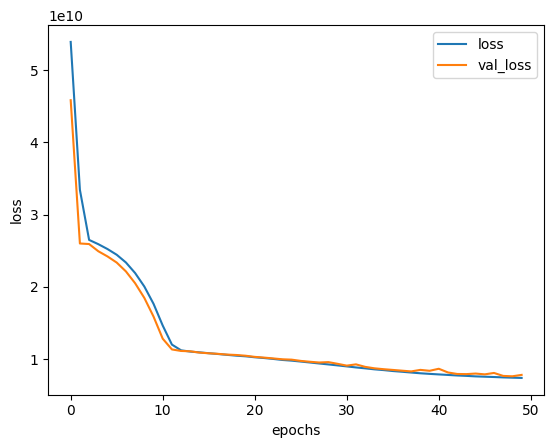

In [25]:
import matplotlib.pyplot as plt

# plot loss history
history_df.plot()

plt.xlabel('epochs')
plt.ylabel('loss');


### Early Stopping (callback)


- Prevent overfitting
- will not waste the computing power
- save time

**Early Stopping** is an optimization technique used to prevent a neural network from overfitting. It functions as an automated circuit breaker that monitors the performance of the model on a validation dataset during training. If the model's performance stops improving for a specified number of epochs, training is halted immediately.

---

### 🚨 The Problem It Solves: Overfitting over Time

During training, as a neural network runs through more epochs, its training loss will almost always continue to decrease because it is actively adapting its weights to fit that specific data.

However, after a certain point, the model stops learning general patterns and begins to memorize noise. When this happens:
* **Training Loss** keeps going down 📉
* **Validation Loss** stops dropping and begins to climb back up 📈

* It relies on three critical configuration metrics:

    1. **`monitor`**: The specific validation metric you want to watch (typically `'val_loss'`).
    2. **`patience`**: The number of epochs the model is allowed to continue training with *no improvement* before hitting the kill switch. For example, if `patience=5`, and the loss doesn't drop for 5 consecutive rounds, training ends.
    3. **`restore_best_weights`**: When set to `True`, Keras automatically rolls back the final model weights to the exact epoch that achieved the lowest validation loss, throwing away the degraded weights from the unhelpful patience rounds.

In [26]:
# import EarlyStopping
from keras.callbacks import EarlyStopping

# configure EarlyStopping parameters
es=EarlyStopping(monitor='val_loss', patience=5,restore_best_weights=True)


In [27]:
# run model and use EarlyStopping in callbacks

#Step 1
model = Sequential()

model.add(Input(shape=(X.shape[1],)))  #input layer with 1 feature
model.add(Dense(30, activation = "relu"))  # hidden layer with 3 neurons (nodes)
model.add(Dense(20, activation = "relu"))  # hidden layer with 20 neurons
model.add(Dense(15, activation = "relu"))  # hidden layer with 15 neurons
model.add(Dense(1, activation = "linear"))  # output layer

#Step 2
model.compile(loss='mse')

#Step 3
history = model.fit(X_train,
                    y_train, 
                    validation_data=(X_val,y_val),
                    epochs=100,
                    batch_size=64,
                    callbacks=[es]
                   )

Epoch 1/100
205/205 [==============================] - 0s 764us/step - loss: 52053590016.0000 - val_loss: 40114266112.0000
Epoch 2/100
205/205 [==============================] - 0s 472us/step - loss: 29825972224.0000 - val_loss: 26227988480.0000
Epoch 3/100
205/205 [==============================] - 0s 465us/step - loss: 26656827392.0000 - val_loss: 25598912512.0000
Epoch 4/100
205/205 [==============================] - 0s 462us/step - loss: 26129367040.0000 - val_loss: 25030289408.0000
Epoch 5/100
205/205 [==============================] - 0s 465us/step - loss: 25436841984.0000 - val_loss: 24342734848.0000
Epoch 6/100
205/205 [==============================] - 0s 467us/step - loss: 24479004672.0000 - val_loss: 23416121344.0000
Epoch 7/100
205/205 [==============================] - 0s 469us/step - loss: 23299885056.0000 - val_loss: 21935419392.0000
Epoch 8/100
205/205 [==============================] - 0s 460us/step - loss: 21660229632.0000 - val_loss: 20078651392.0000
Epoch 9/100
205/

Epoch 68/100
205/205 [==============================] - 0s 451us/step - loss: 6178364928.0000 - val_loss: 6210399232.0000
Epoch 69/100
205/205 [==============================] - 0s 459us/step - loss: 6140547584.0000 - val_loss: 6629710336.0000
Epoch 70/100
205/205 [==============================] - 0s 463us/step - loss: 6095934976.0000 - val_loss: 6229834752.0000
Epoch 71/100
205/205 [==============================] - 0s 471us/step - loss: 6055154176.0000 - val_loss: 6851539456.0000
Epoch 72/100
205/205 [==============================] - 0s 458us/step - loss: 5990690816.0000 - val_loss: 6025735168.0000
Epoch 73/100
205/205 [==============================] - 0s 460us/step - loss: 5937519616.0000 - val_loss: 5939619328.0000
Epoch 74/100
205/205 [==============================] - 0s 465us/step - loss: 5913223168.0000 - val_loss: 6943804416.0000
Epoch 75/100
205/205 [==============================] - 0s 455us/step - loss: 5856083456.0000 - val_loss: 5842481664.0000
Epoch 76/100
205/205 [==

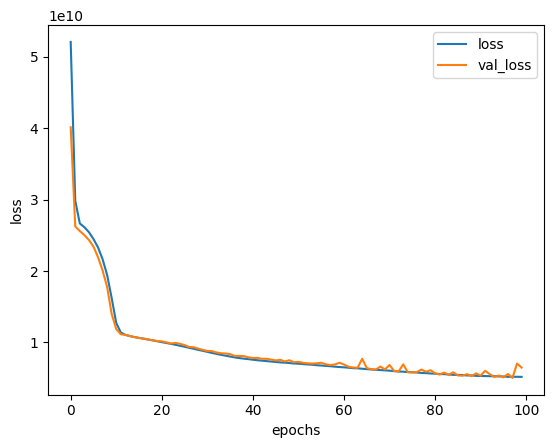

In [28]:
# define history df again
history_df = pd.DataFrame(history.history)

history_df.plot()
plt.xlabel("epochs")
plt.ylabel("loss");

The model is Underfitting
- More complex model
- More data (features)

## Optimizers & Learning Rate

An optimizer is the algorithm responsible for updating the neural network's weights to minimize the loss function.

- **Adam**: Popular default choice. Combines momentum and adaptive learning rates.
- **SGD**: Standard Stochastic Gradient Descent. Updates weights using gradients and a learning rate. Often combined with momentum.
- **RMSprop**: Adapts the effective learning rate for each weight based on previous squared gradients.

The learning rate ($\alpha$) controls how large each update step is:

- **Too high**: May overshoot the minimum or cause unstable training.
- **Too low**: Training may become very slow.
- **Good learning rate**: Allows steady progress toward the minimum.


**Tip:** 

_Start with Adam (learning_rate=0.001). If training performance is unsatisfactory, experiment with other optimizers and learning rates._


In [29]:
from keras.optimizers import Adam

#Step 1

model = Sequential()

model.add(Input(shape=(X.shape[1],)))  #input layer with 1 feature
model.add(Dense(30, activation = "relu"))  # hidden layer with 3 neurons (nodes)
model.add(Dense(20, activation = "relu"))  # hidden layer with 20 neurons
model.add(Dense(15, activation = "relu"))  # hidden layer with 15 neurons
model.add(Dense(1, activation = "linear"))  # output layer

#Step 2: Instantiate a custom optimizer

optimizer = Adam(learning_rate=0.01)  # Default Adam LR = 0.001

model.compile(
            loss='mse', 
            optimizer=optimizer)

#Step 3: Fitting with early stopping

es=EarlyStopping(monitor='val_loss', 
                 patience=5,
                 restore_best_weights=True)

history = model.fit(
                    X_train,
                    y_train, 
                    validation_data=(X_val,y_val),
                    epochs=100,
                    batch_size=64,
                    callbacks=[es])

Epoch 1/100
205/205 [==============================] - 0s 829us/step - loss: 26204887040.0000 - val_loss: 14477062144.0000
Epoch 2/100
205/205 [==============================] - 0s 567us/step - loss: 11168665600.0000 - val_loss: 10872798208.0000
Epoch 3/100
205/205 [==============================] - 0s 579us/step - loss: 10022340608.0000 - val_loss: 9902301184.0000
Epoch 4/100
205/205 [==============================] - 0s 568us/step - loss: 9146680320.0000 - val_loss: 9147269120.0000
Epoch 5/100
205/205 [==============================] - 0s 576us/step - loss: 8379949056.0000 - val_loss: 8309360640.0000
Epoch 6/100
205/205 [==============================] - 0s 574us/step - loss: 8043155456.0000 - val_loss: 8118456320.0000
Epoch 7/100
205/205 [==============================] - 0s 568us/step - loss: 7788036608.0000 - val_loss: 8015847936.0000
Epoch 8/100
205/205 [==============================] - 0s 572us/step - loss: 7274931200.0000 - val_loss: 7258387968.0000
Epoch 9/100
205/205 [======

Text(0, 0.5, 'loss')

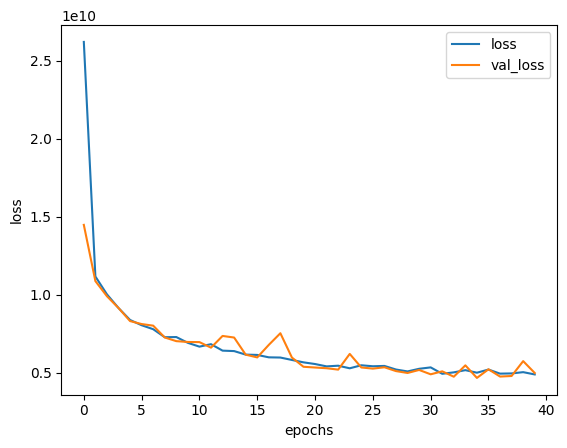

In [30]:
# Plot loss vs val_loss

history_df = pd.DataFrame(history.history)

history_df.plot()
plt.xlabel("epochs")
plt.ylabel("loss")


## Data Scaling

### Why is Feature Scaling Important in Deep Learning?

- **Faster Convergence**: Helps gradient descent find good weights faster by reducing differences in gradient sizes and improving the path toward the minimum.
- **Balanced Feature Influence**: Prevents features with large numerical values from dominating gradients simply because of their scale.
- **Easier Learning Rate Tuning**: Features on similar scales tend to produce more balanced gradients, making it easier to find a suitable learning rate.

In [31]:
# Scale your data before fitting your model

from sklearn.preprocessing import StandardScaler

# Initialize the scaler
scaler = StandardScaler()

# Fit only on training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform validation and test data
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [32]:
#The final version


#Step 1

model = Sequential()

model.add(Input(shape=(X.shape[1],)))  #input layer with 1 feature
model.add(Dense(30, activation = "relu"))  # hidden layer with 3 neurons (nodes)
model.add(Dense(20, activation = "relu"))  # hidden layer with 20 neurons
model.add(Dense(15, activation = "relu"))  # hidden layer with 15 neurons
model.add(Dense(1, activation = "linear"))  # output layer

#Step 2: Instantiate a custom optimizer

optimizer = Adam(learning_rate=0.01)  # Default Adam LR = 0.001

model.compile(
            loss='mse', 
            optimizer=optimizer)

#Step 3: Fitting with early stopping

es=EarlyStopping(monitor='val_loss', 
                 patience=5,
                 restore_best_weights=True)

history = model.fit(
                    X_train_scaled,
                    y_train, 
                    validation_data=(X_val_scaled,y_val),
                    epochs=100,
                    batch_size=64,
                    callbacks=[es])

Epoch 1/100
205/205 [==============================] - 0s 907us/step - loss: 34521694208.0000 - val_loss: 9562888192.0000
Epoch 2/100
205/205 [==============================] - 0s 619us/step - loss: 7490454016.0000 - val_loss: 5937466880.0000
Epoch 3/100
205/205 [==============================] - 0s 618us/step - loss: 5279379456.0000 - val_loss: 4672125440.0000
Epoch 4/100
205/205 [==============================] - 0s 646us/step - loss: 4667893760.0000 - val_loss: 4339523584.0000
Epoch 5/100
205/205 [==============================] - 0s 639us/step - loss: 4528750592.0000 - val_loss: 4304485376.0000
Epoch 6/100
205/205 [==============================] - 0s 642us/step - loss: 4487325184.0000 - val_loss: 4240876800.0000
Epoch 7/100
205/205 [==============================] - 0s 626us/step - loss: 4458719744.0000 - val_loss: 4185116928.0000
Epoch 8/100
205/205 [==============================] - 0s 621us/step - loss: 4421092352.0000 - val_loss: 4166055424.0000
Epoch 9/100
205/205 [==========

Text(0, 0.5, 'loss')

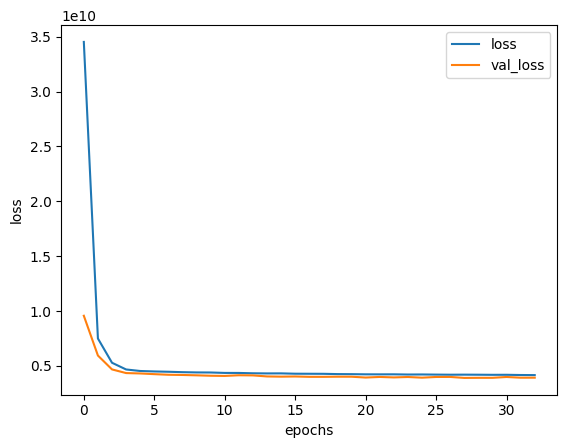

In [33]:
# Plot loss vs val_loss

history_df = pd.DataFrame(history.history)

history_df.plot()
plt.xlabel("epochs")
plt.ylabel("loss")

## Another way to write the Seq models

In [34]:
# one way
model=Sequential()
model.add(Input(shape=(1,)))
model.add(Dense(3))  # hidden layer
model.add(Dense(1))  # output


In [35]:
# the other way
model=Sequential([
    Input(shape=(1,)),   # input layer
    Dense(3),  # hidden layer
    Dense(1)   # output layer
])
